# Customer Feedback Classification

Notebook eksperimen klasifikasi sentimen feedback pelanggan menggunakan TF-IDF dan beberapa model machine learning.

In [1]:
# Instalasi dependency utama jika diperlukan
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Setup dan Library

In [2]:
from pathlib import Path
import json
import re
import shutil
import joblib

import mlflow
import mlflow.sklearn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display

from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from sklearn.metrics import make_scorer

## Konfigurasi

In [3]:
DATA_DIR = Path("data")
ARTIFACT_DIR = Path("artifacts")
MODEL_DIR = Path("models")

DATA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

CSV_PATH = DATA_DIR / "20191002-reviews.csv"

TEXT_COLUMN = "reviewContent"
RATING_COLUMN = "rating"
TARGET_COLUMN = "sentiment"

LABEL_MAP = {
    1: "Negative",
    2: "Negative",
    4: "Positive",
    5: "Positive"
}

print("CSV:", CSV_PATH.resolve())


CSV: C:\Users\Naufal\Documents\AI\Banglore\final-project\data\20191002-reviews.csv


## Konfigurasi MLflow

In [4]:
MLFLOW_DB = Path("mlflow.db").resolve()
MLFLOW_URI = f"sqlite:///{MLFLOW_DB}"

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow_experiment = mlflow.set_experiment("customer-feedback-sentiment")

print({
    "mlflow_version": mlflow.__version__,
    "tracking_uri": mlflow.get_tracking_uri(),
    "experiment_id": mlflow_experiment.experiment_id
})


{'mlflow_version': '2.22.5', 'tracking_uri': 'sqlite:///C:\\Users\\Naufal\\Documents\\AI\\Banglore\\final-project\\mlflow.db', 'experiment_id': '1'}


## Load Dataset

In [5]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {CSV_PATH}\n"
        "Letakkan 20191002-reviews.csv di folder data/"
    )

raw_df = pd.read_csv(CSV_PATH)

display(raw_df.head(10))
print("Shape:", raw_df.shape)
raw_df.info()


,itemId,category,name,rating,originalRating,reviewTitle,reviewContent,likeCount,upVotes,downVotes,helpful,relevanceScore,boughtDate,clientType,retrievedDate
0,100002528,beli-harddisk-eksternal,Kamal U.,5,NaN,NaN,bagus mantap dah sesui pesanan,0,0,0,True,26.5100,09 Apr 2019,androidApp,2019-10-02
1,100002528,beli-harddisk-eksternal,yofanca m.,4,NaN,NaN,"Bagus, sesuai foto",0,0,0,True,22.4900,24 Sep 2017,androidApp,2019-10-02
2,100002528,beli-harddisk-eksternal,Lazada Customer,5,NaN,ok mantaaapppp barang sesuai pesanan.. good,okkkkk mantaaaaaaapppp ... goood,0,0,0,True,21.5000,04 Apr 2018,androidApp,2019-10-02
3,100002528,beli-harddisk-eksternal,Lazada Customer,4,NaN,NaN,bagus sesuai,0,0,0,True,20.5100,22 Sep 2017,androidApp,2019-10-02
4,100002528,beli-harddisk-eksternal,Yosep M.,5,NaN,NaN,NaN,0,0,0,True,16.0100,17 Agu 2018,androidApp,2019-10-02
5,100002528,beli-harddisk-eksternal,Deden,5,NaN,NaN,NaN,0,0,0,True,16.0100,02 Nov 2017,androidApp,2019-10-02
6,100002528,beli-harddisk-eksternal,Yeana,5,NaN,NaN,NaN,0,0,0,True,13.0100,25 Sep 2017,mobile,2019-10-02
7,100002528,beli-harddisk-eksternal,nurfarida,1,NaN,ada pengirimn ntb bima,bima,4,4,0,True,7.2200,NaN,androidApp,2019-10-02
8,100003785,beli-harddisk-eksternal,Fadjar B.,1,NaN,NaN,baru 10 bulan layarnya dah bergaris,0,0,0,True,21.4900,06 Apr 2017,androidApp,2019-10-02
9,100003785,beli-harddisk-eksternal,agung p.,5,NaN,Barang bagus sesuai specs,"Pesan rabu sore,minggu sore sampe,,barang sesu...",0,0,0,True,19.5000,01 Mar 2017,mobile,2019-10-02


Shape: (203787, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203787 entries, 0 to 203786
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   itemId          203787 non-null  int64  
 1   category        203787 non-null  object 
 2   name            203787 non-null  object 
 3   rating          203787 non-null  int64  
 4   originalRating  8 non-null       float64
 5   reviewTitle     23399 non-null   object 
 6   reviewContent   107029 non-null  object 
 7   likeCount       203787 non-null  int64  
 8   upVotes         203787 non-null  int64  
 9   downVotes       203787 non-null  int64  
 10  helpful         203787 non-null  bool   
 11  relevanceScore  203787 non-null  float64
 12  boughtDate      196680 non-null  object 
 13  clientType      203787 non-null  object 
 14  retrievedDate   203787 non-null  object 
dtypes: bool(1), float64(2), int64(5), object(7)
memory usage: 22.0+ MB


## Overview Dataset

In [6]:
overview = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean() * 100,
    "unique_count": raw_df.nunique(dropna=True)
})

display(overview)

display(raw_df.describe(include="all").T)


,dtype,missing_count,missing_percent,unique_count
itemId,int64,0,0.0000,4422
category,object,0,0.0000,5
name,object,0,0.0000,40099
rating,int64,0,0.0000,5
originalRating,float64,203779,99.9961,1
reviewTitle,object,180388,88.5179,5724
reviewContent,object,96758,47.4800,38071
likeCount,int64,0,0.0000,125
upVotes,int64,0,0.0000,125
downVotes,int64,0,0.0000,57


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
itemId,"203,787.0000",NaN,NaN,NaN,"283,647,856.6479","172,620,746.1330","6,068.0000","160,008,566.0000","354,115,963.0000","414,742,098.0000","724,216,967.0000"
category,203787,5,beli-harddisk-eksternal,82223,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,203787,40099,Lazada Customer,46731,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,"203,787.0000",NaN,NaN,NaN,4.6032,0.9912,1.0000,5.0000,5.0000,5.0000,5.0000
originalRating,8.0000,NaN,NaN,NaN,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
reviewTitle,23399,5724,Lima Bintang,656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reviewContent,107029,38071,bagus,648,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likeCount,"203,787.0000",NaN,NaN,NaN,0.6686,12.1924,-1.0000,0.0000,0.0000,0.0000,"1,776.0000"
upVotes,"203,787.0000",NaN,NaN,NaN,0.6686,12.1924,-1.0000,0.0000,0.0000,0.0000,"1,776.0000"
downVotes,"203,787.0000",NaN,NaN,NaN,0.1646,2.0133,0.0000,0.0000,0.0000,0.0000,111.0000


## Validasi Kolom

In [7]:
required_columns = [TEXT_COLUMN, RATING_COLUMN]

missing_required = [
    col for col in required_columns
    if col not in raw_df.columns
]

if missing_required:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {missing_required}. "
        f"Kolom yang tersedia: {raw_df.columns.tolist()}"
    )

print("Kolom utama tersedia.")


Kolom utama tersedia.


## Audit Data

In [8]:
data = raw_df.copy()

print("Duplicate rows:", data.duplicated().sum())
print("Missing reviewContent:", data[TEXT_COLUMN].isna().sum())
print("Missing rating:", data[RATING_COLUMN].isna().sum())

print("\nDistribusi rating:")
display(data[RATING_COLUMN].value_counts(dropna=False).sort_index())


Duplicate rows: 3113
Missing reviewContent: 96758
Missing rating: 0

Distribusi rating:


rating
1      9749
2      3382
3      7073
4     17567
5    166016
Name: count, dtype: int64

## Data Cleaning

In [9]:
data = data.dropna(subset=[TEXT_COLUMN, RATING_COLUMN]).copy()

data[TEXT_COLUMN] = data[TEXT_COLUMN].astype(str).str.strip()

before_empty = len(data)
data = data[data[TEXT_COLUMN].str.len() > 0].copy()

data[RATING_COLUMN] = pd.to_numeric(data[RATING_COLUMN], errors="coerce")
data = data.dropna(subset=[RATING_COLUMN]).copy()

data[RATING_COLUMN] = data[RATING_COLUMN].astype(int)

valid_ratings = [1, 2, 3, 4, 5]
data = data[data[RATING_COLUMN].isin(valid_ratings)].copy()

data = data.drop_duplicates(subset=[TEXT_COLUMN, RATING_COLUMN]).reset_index(drop=True)

print("Shape setelah cleaning:", data.shape)
print("Duplicate tersisa:", data.duplicated().sum())


Shape setelah cleaning: (38341, 15)
Duplicate tersisa: 0


## Binary Labeling

In [10]:
data[TARGET_COLUMN] = data[RATING_COLUMN].map(LABEL_MAP)

# Rating 3 tidak memiliki label binary sehingga dikeluarkan.
data = data.dropna(subset=[TARGET_COLUMN]).reset_index(drop=True)

print("Distribusi sentiment:")
display(data[TARGET_COLUMN].value_counts())

print("\nProporsi sentiment (%):")
display(data[TARGET_COLUMN].value_counts(normalize=True).mul(100))


Distribusi sentiment:


sentiment
Positive    33224
Negative     3467
Name: count, dtype: int64


Proporsi sentiment (%):


sentiment
Positive   90.5508
Negative    9.4492
Name: proportion, dtype: float64

## Audit Setelah Labeling

In [11]:
audit_after_labeling = pd.DataFrame({
    "count": data[[TEXT_COLUMN, RATING_COLUMN, TARGET_COLUMN]].count(),
    "missing": data[[TEXT_COLUMN, RATING_COLUMN, TARGET_COLUMN]].isna().sum()
})

display(audit_after_labeling)
print("Final shape:", data.shape)


,count,missing
reviewContent,36691,0
rating,36691,0
sentiment,36691,0


Final shape: (36691, 16)


## Text Cleaning

In [12]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@[A-Za-z0-9_]+", " ", text)
    text = re.sub(r"#[A-Za-z0-9_]+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-zA-ZÀ-ÿ\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["clean_text"] = data[TEXT_COLUMN].apply(clean_text)

empty_after_cleaning = (data["clean_text"].str.len() == 0).sum()
print("Empty text:", empty_after_cleaning)

data = data[data["clean_text"].str.len() > 0].reset_index(drop=True)

print("Final dataset:", data.shape)


Empty text: 59
Final dataset: (36632, 17)


## Text Normalization

In [13]:
normalization_dict = {
    "bgt": "banget",
    "yg": "yang",
    "yng": "yang",
    "dgn": "dengan",
    "dr": "dari",
    "tp": "tetapi",
    "tpi": "tetapi",
    "krn": "karena",
    "karna": "karena",
    "gk": "tidak",
    "ga": "tidak",
    "gak": "tidak",
    "ngga": "tidak",
    "nggak": "tidak",
    "tdk": "tidak",
    "tak": "tidak",
    "blm": "belum",
    "udh": "sudah",
    "sdh": "sudah",
    "dah": "sudah",
    "sm": "sama",
    "spt": "seperti",
    "aja": "saja",
    "kalo": "kalau",
    "kl": "kalau",
    "jg": "juga",
    "jd": "jadi",
    "bkn": "bukan",
    "krg": "kurang",
    "hrs": "harus"
}

def normalize_text(text):
    tokens = text.split()
    tokens = [normalization_dict.get(token, token) for token in tokens]
    return " ".join(tokens)

data["normalized_text"] = data["clean_text"].apply(normalize_text)

display(
    data[[TEXT_COLUMN, "clean_text", "normalized_text", TARGET_COLUMN]]
    .head(10)
)


,reviewContent,clean_text,normalized_text,sentiment
0,bagus mantap dah sesui pesanan,bagus mantap dah sesui pesanan,bagus mantap sudah sesui pesanan,Positive
1,"Bagus, sesuai foto",bagus sesuai foto,bagus sesuai foto,Positive
2,okkkkk mantaaaaaaapppp ... goood,okkkkk mantaaaaaaapppp goood,okkkkk mantaaaaaaapppp goood,Positive
3,bagus sesuai,bagus sesuai,bagus sesuai,Positive
4,bima,bima,bima,Negative
5,baru 10 bulan layarnya dah bergaris,baru bulan layarnya dah bergaris,baru bulan layarnya sudah bergaris,Negative
6,"Pesan rabu sore,minggu sore sampe,,barang sesu...",pesan rabu sore minggu sore sampe barang sesua...,pesan rabu sore minggu sore sampe barang sesua...,Positive
7,"Mau tanya ini cicilnya pake apa ya,cc bkn?",mau tanya ini cicilnya pake apa ya cc bkn,mau tanya ini cicilnya pake apa ya cc bukan,Negative
8,Apakah TV. Tsb. Suda ada anti gores..,apakah tv tsb suda ada anti gores,apakah tv tsb suda ada anti gores,Positive
9,Pengirim barang tidak sesuai janji. Katanya ex...,pengirim barang tidak sesuai janji katanya exp...,pengirim barang tidak sesuai janji katanya exp...,Negative


## Tokenization dan Stopword Removal

In [14]:
# Stopword Bahasa Indonesia yang umum.
# Kata negasi penting seperti tidak dan bukan sengaja dipertahankan.
indonesian_stopwords = {
    "yang", "dan", "di", "ke", "dari", "untuk", "dengan",
    "ini", "itu", "pada", "adalah", "sebagai", "karena",
    "atau", "juga", "sudah", "akan", "ada", "dalam",
    "saya", "aku", "kami", "kita", "mereka", "dia",
    "nya", "saja", "lebih", "sangat", "bisa", "dapat",
    "oleh", "jadi", "agar", "buat", "seperti", "sama",
    "kalau", "ketika", "saat", "dengan"
}

# Pertahankan kata yang memiliki nilai sentimen/negasi.
indonesian_stopwords -= {
    "tidak", "bukan", "belum", "kurang", "bagus", "buruk"
}

def tokenize_and_remove_stopwords(text):
    tokens = text.split()
    tokens = [token for token in tokens if token not in indonesian_stopwords]
    return " ".join(tokens)

data["processed_text"] = data["normalized_text"].apply(
    tokenize_and_remove_stopwords
)

data = data[data["processed_text"].str.len() > 0].reset_index(drop=True)

display(
    data[[TEXT_COLUMN, "normalized_text", "processed_text", TARGET_COLUMN]]
    .head(10)
)


,reviewContent,normalized_text,processed_text,sentiment
0,bagus mantap dah sesui pesanan,bagus mantap sudah sesui pesanan,bagus mantap sesui pesanan,Positive
1,"Bagus, sesuai foto",bagus sesuai foto,bagus sesuai foto,Positive
2,okkkkk mantaaaaaaapppp ... goood,okkkkk mantaaaaaaapppp goood,okkkkk mantaaaaaaapppp goood,Positive
3,bagus sesuai,bagus sesuai,bagus sesuai,Positive
4,bima,bima,bima,Negative
5,baru 10 bulan layarnya dah bergaris,baru bulan layarnya sudah bergaris,baru bulan layarnya bergaris,Negative
6,"Pesan rabu sore,minggu sore sampe,,barang sesu...",pesan rabu sore minggu sore sampe barang sesua...,pesan rabu sore minggu sore sampe barang sesua...,Positive
7,"Mau tanya ini cicilnya pake apa ya,cc bkn?",mau tanya ini cicilnya pake apa ya cc bukan,mau tanya cicilnya pake apa ya cc bukan,Negative
8,Apakah TV. Tsb. Suda ada anti gores..,apakah tv tsb suda ada anti gores,apakah tv tsb suda anti gores,Positive
9,Pengirim barang tidak sesuai janji. Katanya ex...,pengirim barang tidak sesuai janji katanya exp...,pengirim barang tidak sesuai janji katanya exp...,Negative


## EDA: Distribusi Sentiment

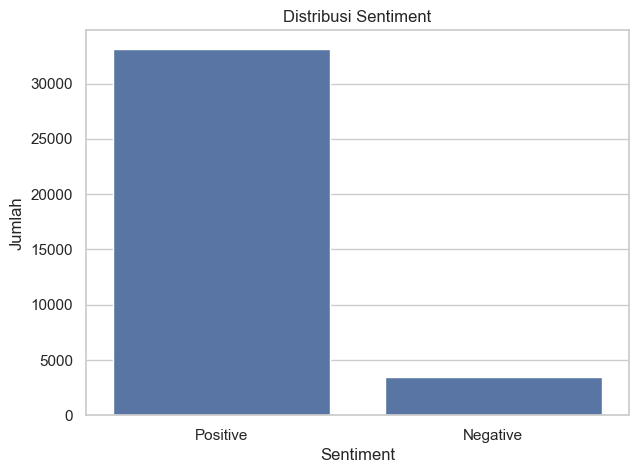

In [15]:
plt.figure(figsize=(7, 5))
sns.countplot(data=data, x=TARGET_COLUMN)
plt.title("Distribusi Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Jumlah")
plt.show()


## EDA: Panjang Teks

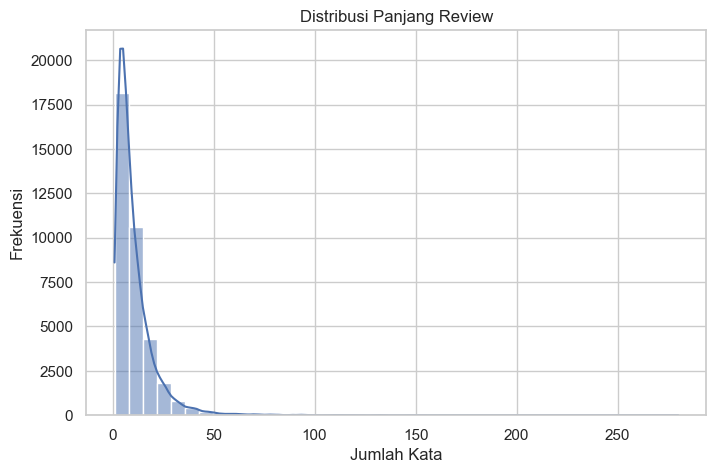

count   36,629.0000
mean        10.4798
std         10.2601
min          1.0000
25%          4.0000
50%          8.0000
75%         13.0000
max        280.0000
Name: text_length, dtype: float64

In [16]:
data["text_length"] = data["processed_text"].str.split().str.len()

plt.figure(figsize=(8, 5))
sns.histplot(data["text_length"], bins=40, kde=True)
plt.title("Distribusi Panjang Review")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.show()

display(data["text_length"].describe())


## Train-Test Split

In [17]:
X = data["processed_text"]
y = data[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:")
display(y_train.value_counts(normalize=True))
print("y_test:")
display(y_test.value_counts(normalize=True))


X_train: (29303,)
X_test : (7326,)
y_train:


sentiment
Positive   0.9055
Negative   0.0945
Name: proportion, dtype: float64

y_test:


sentiment
Positive   0.9055
Negative   0.0945
Name: proportion, dtype: float64

## Feature Extraction: TF-IDF

In [18]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    norm="l2"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("X_train TF-IDF:", X_train_tfidf.shape)
print("X_test TF-IDF :", X_test_tfidf.shape)
print("Vocabulary    :", len(tfidf.vocabulary_))


X_train TF-IDF: (29303, 32339)
X_test TF-IDF : (7326, 32339)
Vocabulary    : 32339


## Definisi Model

In [19]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Models:", list(models.keys()))


Models: ['Logistic Regression', 'Naive Bayes', 'Linear SVM', 'Random Forest']


## Training Model

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

f1_positive_scorer = make_scorer(f1_score, pos_label="Positive")

cv_scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(precision_score, pos_label="Positive"),
    "recall": make_scorer(recall_score, pos_label="Positive"),
    "f1": f1_positive_scorer,
}

cv_results = {}

for name, model in models.items():
    print(f"Training with 5-Fold CV: {name}")

    scores = cross_validate(
        model, X_train_tfidf, y_train, cv=cv, scoring=cv_scoring, n_jobs=-1
    )

    cv_results[name] = scores

    print(
        f"Accuracy: {scores['test_accuracy'].mean():.4f} | "
        f"Precision: {scores['test_precision'].mean():.4f} | "
        f"Recall: {scores['test_recall'].mean():.4f} | "
        f"F1: {scores['test_f1'].mean():.4f}"
    )

print("Semua default model selesai dilatih menggunakan 5-Fold Cross Validation.")


Training with 5-Fold CV: Logistic Regression
Accuracy: 0.9334 | Precision: 0.9409 | Recall: 0.9886 | F1: 0.9641
Training with 5-Fold CV: Naive Bayes
Accuracy: 0.9196 | Precision: 0.9210 | Recall: 0.9967 | F1: 0.9574
Training with 5-Fold CV: Linear SVM
Accuracy: 0.9413 | Precision: 0.9562 | Recall: 0.9801 | F1: 0.9680
Training with 5-Fold CV: Random Forest
Accuracy: 0.9279 | Precision: 0.9346 | Recall: 0.9896 | F1: 0.9613
Semua default model selesai dilatih menggunakan 5-Fold Cross Validation.


## Hyperparameter Tuning

In [21]:
## Hyperparameter Tuning

f1_positive_scorer = make_scorer(f1_score, pos_label="Positive")

tuning_spaces = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        "params": {
            "C": np.logspace(-2, 2, 10),
            "class_weight": [None, "balanced"],
            "solver": ["liblinear", "lbfgs"],
        },
    },
    "Naive Bayes": {
        "model": MultinomialNB(),
        "params": {"alpha": np.logspace(-3, 1, 12)},
    },
    "Linear SVM": {
        "model": LinearSVC(random_state=RANDOM_STATE),
        "params": {"C": np.logspace(-2, 2, 10), "class_weight": [None, "balanced"]},
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        "params": {
            "n_estimators": [200, 300, 500],
            "max_depth": [None, 10, 20, 30],
            "min_samples_split": [2, 5, 10],
            "class_weight": [None, "balanced"],
        },
    },
}

tuned_models = {}
tuning_rows = []

for name, config in tuning_spaces.items():
    print(f"Tuning: {name}")

    search = RandomizedSearchCV(
        estimator=config["model"],
        param_distributions=config["params"],
        n_iter=10,
        scoring=f1_positive_scorer,
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
    )

    search.fit(X_train_tfidf, y_train)

    tuned_models[name] = search.best_estimator_

    tuning_rows.append(
        {
            "Model": name,
            "Best CV F1": search.best_score_,
            "Best Parameters": search.best_params_,
        }
    )

tuning_df = (
    pd.DataFrame(tuning_rows)
    .sort_values("Best CV F1", ascending=False)
    .reset_index(drop=True)
)

display(tuning_df)


Tuning: Logistic Regression
Tuning: Naive Bayes
Tuning: Linear SVM
Tuning: Random Forest


,Model,Best CV F1,Best Parameters
0,Linear SVM,0.9686,"{'class_weight': None, 'C': 0.5994842503189409}"
1,Naive Bayes,0.9674,{'alpha': 0.02848035868435802}
2,Logistic Regression,0.9664,"{'solver': 'lbfgs', 'class_weight': None, 'C':..."
3,Random Forest,0.9616,"{'n_estimators': 200, 'min_samples_split': 2, ..."


## Final Model Evaluation

In [22]:
final_rows = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test_tfidf)

    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="Positive"),
        "Recall": recall_score(y_test, y_pred, pos_label="Positive"),
        "F1": f1_score(y_test, y_pred, pos_label="Positive")
    })

final_results = (
    pd.DataFrame(final_rows)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(final_results)


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Linear SVM,0.9499,0.8086,0.9626,0.9828,0.9726
1,Naive Bayes,0.9485,0.8305,0.9674,0.9760,0.9717
2,Logistic Regression,0.9438,0.8046,0.9623,0.9762,0.9692
3,Random Forest,0.9350,0.7001,0.9415,0.9897,0.9650


In [23]:
best_model_name = final_results.loc[0, "Model"]
best_model = tuned_models[best_model_name]

print("Best model:", best_model_name)


Best model: Linear SVM


## Train vs Test Evaluation

In [24]:
train_pred = best_model.predict(X_train_tfidf)
test_pred = best_model.predict(X_test_tfidf)

train_metrics = {
    "Accuracy": accuracy_score(y_train, train_pred),
    "Precision": precision_score(y_train, train_pred, pos_label="Positive"),
    "Recall": recall_score(y_train, train_pred, pos_label="Positive"),
    "F1": f1_score(y_train, train_pred, pos_label="Positive")
}

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, pos_label="Positive"),
    "Recall": recall_score(y_test, test_pred, pos_label="Positive"),
    "F1": f1_score(y_test, test_pred, pos_label="Positive")
}

train_test_df = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Train", "Test"]
)

display(train_test_df)


,Accuracy,Precision,Recall,F1
Train,0.9860,0.9893,0.9953,0.9923
Test,0.9499,0.9626,0.9828,0.9726


## Confusion Matrix

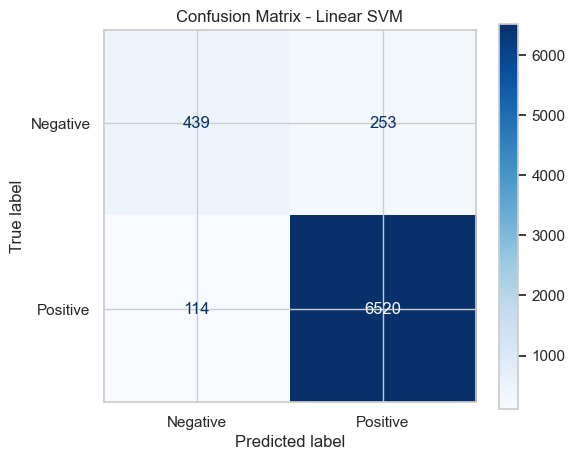

In [25]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    cmap="Blues",
    ax=ax
)
ax.set_title(f"Confusion Matrix - {best_model_name}")
plt.show()


## ROC-AUC dan Precision-Recall

ROC-AUC: 0.9639047445198234
Average Precision: 0.995350854580879


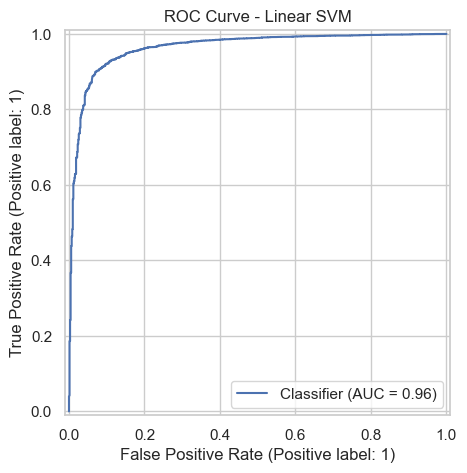

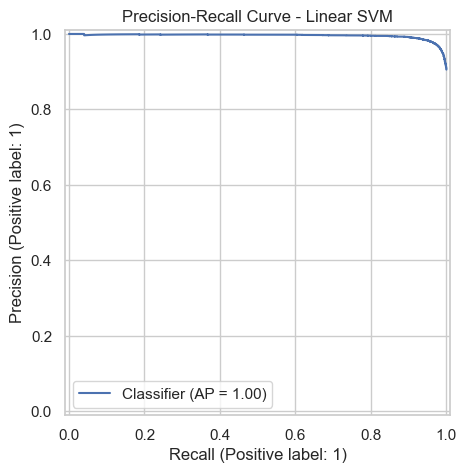

In [26]:
def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]

    if hasattr(model, "decision_function"):
        return model.decision_function(X)

    return None

positive_class_index = list(best_model.classes_).index("Positive")
y_score = get_scores(best_model, X_test_tfidf)

if y_score is not None:
    y_binary = (y_test == "Positive").astype(int)

    roc_auc = roc_auc_score(y_binary, y_score)
    avg_precision = average_precision_score(y_binary, y_score)

    print("ROC-AUC:", roc_auc)
    print("Average Precision:", avg_precision)

    fig, ax = plt.subplots(figsize=(7, 5))
    RocCurveDisplay.from_predictions(
        y_binary,
        y_score,
        ax=ax
    )
    ax.set_title(f"ROC Curve - {best_model_name}")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))
    PrecisionRecallDisplay.from_predictions(
        y_binary,
        y_score,
        ax=ax
    )
    ax.set_title(f"Precision-Recall Curve - {best_model_name}")
    plt.show()
else:
    roc_auc = np.nan
    avg_precision = np.nan
    print("Model tidak menyediakan decision score/probability.")


## Error Analysis

In [27]:
error_analysis = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(test_pred)
})

error_analysis = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

print("Jumlah salah prediksi:", len(error_analysis))

display(error_analysis.head(20))


Jumlah salah prediksi: 367


,text,actual,predicted
3,kondisi laptop gmn mohon dijelaskan detail thx,Negative,Positive
11,mohon maaf sebelumnya beli cod pas barang samp...,Negative,Positive
38,tv beli flash sale bulan lalu sebulan pemakaia...,Negative,Positive
46,kecewa deh barang ditukar model lain pesanan l...,Negative,Positive
51,produk lucu tetapi flashdisk tidak terbaca lap...,Positive,Negative
64,awal emang tidak ber ekspetasi tinggi tab niat...,Negative,Positive
81,expedisi prosesnya lama banget gan,Negative,Positive
91,kecewa tida menyimpan pail parah,Positive,Negative
98,pass,Negative,Positive
153,sesuai ekspetasi flash disk kencang begitu col...,Positive,Negative


## Feature Importance

In [28]:
if hasattr(best_model, "coef_"):
    feature_names = tfidf.get_feature_names_out()
    coefficients = best_model.coef_[0]

    feature_importance = pd.DataFrame({
        "feature": feature_names,
        "coefficient": coefficients
    })

    positive_features = (
        feature_importance
        .sort_values("coefficient", ascending=False)
        .head(20)
    )

    negative_features = (
        feature_importance
        .sort_values("coefficient", ascending=True)
        .head(20)
    )

    display(positive_features)
    display(negative_features)

elif hasattr(best_model, "feature_importances_"):
    feature_names = tfidf.get_feature_names_out()

    feature_importance = pd.DataFrame({
        "feature": feature_names,
        "importance": best_model.feature_importances_
    }).sort_values("importance", ascending=False)

    display(feature_importance.head(30))
else:
    print("Feature importance langsung tidak tersedia untuk model ini.")


,feature,coefficient
29810,tidak mengecewakan,2.1702
5368,cepat,1.6837
10162,good,1.5914
22762,puas,1.5790
26114,sesuai,1.5712
13357,keren,1.4788
29290,thanks,1.4290
7876,dipake tidak,1.4239
29942,tidak rusak,1.4214
29731,tidak kecewa,1.4041


,feature,coefficient
23941,rusak,-1.9198
12908,kecewa,-1.8471
29495,tidak,-1.7798
29976,tidak sesuai,-1.7298
9467,gabisa,-1.7256
20904,pecah,-1.6950
3607,belum sampai,-1.6945
17455,mengecewakan,-1.5224
3170,batalkan,-1.5108
9047,file,-1.5029


## MLflow Final Tracking

In [29]:
## MLflow Experiment Tracking

from mlflow.tracking import MlflowClient

# Gunakan experiment yang sama
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment("customer-feedback-sentiment")


def evaluate_model(model, X, y):
    pred = model.predict(X)

    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred, pos_label="Positive"),
        "recall": recall_score(y, pred, pos_label="Positive"),
        "f1": f1_score(y, pred, pos_label="Positive"),
    }





for name, model in tuned_models.items():
    metrics = evaluate_model(model, X_test_tfidf, y_test)

    with mlflow.start_run(run_name=f"{name} - Tuned"):
        mlflow.log_param("model_name", name)

        mlflow.log_param("model_stage", "Tuned")

        mlflow.log_param("text_column", TEXT_COLUMN)

        mlflow.log_param("target_column", TARGET_COLUMN)

        # Ambil parameter hasil tuning
        model_params = model.get_params()

        for param_name, param_value in model_params.items():
            # MLflow hanya menerima tipe parameter sederhana
            if isinstance(param_value, (str, int, float, bool)) or param_value is None:
                mlflow.log_param(param_name, param_value)

        # Best CV F1 dari tuning
        tuning_row = tuning_df[tuning_df["Model"] == name].iloc[0]

        mlflow.log_metric("best_cv_f1", float(tuning_row["Best CV F1"]))

        mlflow.log_metrics(metrics)

        mlflow.sklearn.log_model(model, artifact_path="model")


print("Semua model berhasil dicatat ke MLflow.")


2026/11/09 15:15:35 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/09 15:15:49 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/09 15:16:05 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/09 15:16:27 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Semua model berhasil dicatat ke MLflow.


## Save Model dan TF-IDF

In [30]:
model_bundle = {
    "model": best_model,
    "tfidf": tfidf,
    "text_column": TEXT_COLUMN,
    "target_column": TARGET_COLUMN,
    "best_model_name": best_model_name,
    "label_map": {
        "Negative": 0,
        "Positive": 1
    }
}

bundle_path = MODEL_DIR / "customer_feedback_sentiment_model.joblib"
joblib.dump(model_bundle, bundle_path)

metadata = {
    "model_name": best_model_name,
    "text_column": TEXT_COLUMN,
    "target_column": TARGET_COLUMN,
    "dataset_rows": int(len(data)),
    "best_metrics": final_results.iloc[0].to_dict()
}

metadata_path = MODEL_DIR / "metadata.json"
metadata_path.write_text(
    json.dumps(metadata, indent=2, default=str),
    encoding="utf-8"
)

print("Model saved:", bundle_path.resolve())
print("Metadata saved:", metadata_path.resolve())


Model saved: C:\Users\Naufal\Documents\AI\Banglore\final-project\models\customer_feedback_sentiment_model.joblib
Metadata saved: C:\Users\Naufal\Documents\AI\Banglore\final-project\models\metadata.json


## Inference

In [31]:
def predict_feedback(text):
    cleaned = clean_text(text)
    normalized = normalize_text(cleaned)
    processed = tokenize_and_remove_stopwords(normalized)

    if not processed.strip():
        raise ValueError("Feedback menjadi kosong setelah preprocessing.")

    vector = tfidf.transform([processed])
    prediction = best_model.predict(vector)[0]

    result = {
        "feedback": text,
        "processed_text": processed,
        "prediction": prediction
    }

    if hasattr(best_model, "predict_proba"):
        result["confidence"] = float(best_model.predict_proba(vector).max())

    return result

samples = [
    "Barangnya bagus banget dan pengiriman cepat",
    "Barang rusak dan sangat mengecewakan"
]

for sample in samples:
    print(predict_feedback(sample))


{'feedback': 'Barangnya bagus banget dan pengiriman cepat', 'processed_text': 'barangnya bagus banget pengiriman cepat', 'prediction': 'Positive'}
{'feedback': 'Barang rusak dan sangat mengecewakan', 'processed_text': 'barang rusak mengecewakan', 'prediction': 'Negative'}


## Export Data Hasil Eksperimen

In [32]:
data_export = data[
    [TEXT_COLUMN, RATING_COLUMN, TARGET_COLUMN, "clean_text",
     "normalized_text", "processed_text"]
].copy()

processed_data_path = ARTIFACT_DIR / "processed_customer_feedback.csv"
data_export.to_csv(processed_data_path, index=False)

final_results_path = ARTIFACT_DIR / "final_model_results.csv"
final_results.to_csv(final_results_path, index=False)

print("Artifacts:")
print(processed_data_path.resolve())
print(final_results_path.resolve())


Artifacts:
C:\Users\Naufal\Documents\AI\Banglore\final-project\artifacts\processed_customer_feedback.csv
C:\Users\Naufal\Documents\AI\Banglore\final-project\artifacts\final_model_results.csv


In [ ]:
git ls-files | ForEach-Object {
    $size = (Get-Item $_).Length
    [PSCustomObject]@{
        SizeMB = [math]::Round($size / 1MB, 2)
        File = $_
    }
} | Sort-Object SizeMB -Descending | Select-Object -First 15